# PaySim · Motif Finding có bằng chứng
## Khánh · Trình bày và kiểm chứng

**Câu hỏi:** có mẫu quan hệ nào giúp tìm ứng viên fraud/laundering tốt hơn chỉ nhìn một giao dịch?

**Dataset:** PaySim, 9.073.900 tài khoản và 6.362.620 giao dịch. `step` là giờ mô phỏng, amount là đơn vị nội bộ; `isFraud` là nhãn đối chiếu.

**Mạch trình bày:** toy → baseline → motif theo thời gian → chọn trên validation → test và phản ví dụ → review PageRank.

Code thuật toán nằm trong các module Python được **import ở từng bước**. Ctrl+click tên hàm/import để đọc source; notebook giữ lời gọi, bảng kết quả và hình. Không sao chép các định nghĩa hàm dài vào phần trình bày.

**Chạy:** Windows `.venv\Scripts\python.exe` → Restart Kernel → Run All. Spark `local[2]`, heap 6 GiB, Windows Job Object giới hạn CPU/RAM và chỉ cho một tác vụ chạy. Mỗi notebook độc lập, chỉ đọc input dataset tương ứng; không xuất CSV/PNG/model vào repo. Temp/checkpoint nằm ngoài repo.


## 1 · Môi trường

`NotebookSession` kiểm tra Windows Python 3.12, JDK 17, dependency pin và tạo Spark. Source: [presentation.py](../src/motif/presentation.py).

**Bảo vệ tài nguyên:** chỉ một notebook/CLI/gate được chạy; đóng kernel trước khi đổi notebook. Windows Job Object giới hạn cả Python/JVM ở tối đa 2 logical CPUs, CPU hard cap 10%, heap 6 GiB và tổng job commit 10 GiB trên máy 32 GiB. Admission giữ khoảng 8 GiB RAM/commit dự phòng; watchdog dừng job khi áp lực tài nguyên kéo dài. Không tự tăng giới hạn hay retry sau resource stop. Chưa có backend GPU được xác minh; CPU temperature không đo được tin cậy nên không có bảo đảm chống lỗi nguồn/tản nhiệt. Cell cuối lưu số đo tài nguyên của chính lần chạy.


In [1]:
from pathlib import Path
import sys
from IPython.display import display

repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'requirements.txt').exists() and (p / 'src').is_dir())
sys.path.insert(0, str(repo))
from src.motif.presentation import NotebookSession
session = NotebookSession.start('paysim')
display(session.runtime)


[RESOURCE] One workload; CPU hard cap 10%; <=2 logical CPUs; job commit cap 10.0 GiB; RAM reserve 7.9 GiB


[RESOURCE] Effective Spark local[2], heap 6144m; spill before increasing RAM


,setting,value
0,dataset,paysim
1,system,Windows
2,python,3.12.10
3,spark,3.5.1
4,graphframes,0.12.2
5,java,17.0.20.1
6,master,local[2]
7,driver_memory,6144m
8,pip_check,PASS
9,cpu_hard_cap_percent,10


## 2 · Hiểu truy vấn bằng toy graph

Mẫu `A → B → C → A` có ba phép xoay. Ba đỉnh phải khác nhau để loại self-loop và vòng hai tài khoản. Toy tự tạo chỉ kiểm tra thuật toán, không phải bằng chứng thực nghiệm fraud.

Source: [toy_cycle.py](../src/motif/toy_cycle.py).


{'status': 'PASS',
 'pattern': '(a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)',
 'vertices': ['A', 'B', 'C'],
 'edges': [['A', 'B'], ['B', 'C'], ['C', 'A']],
 'raw_match_count': 3,
 'raw_matches': [['A', 'B', 'C'], ['B', 'C', 'A'], ['C', 'A', 'B']],
 'unique_cycle_count': 1,
 'unique_cycles': [['A', 'B', 'C']]}

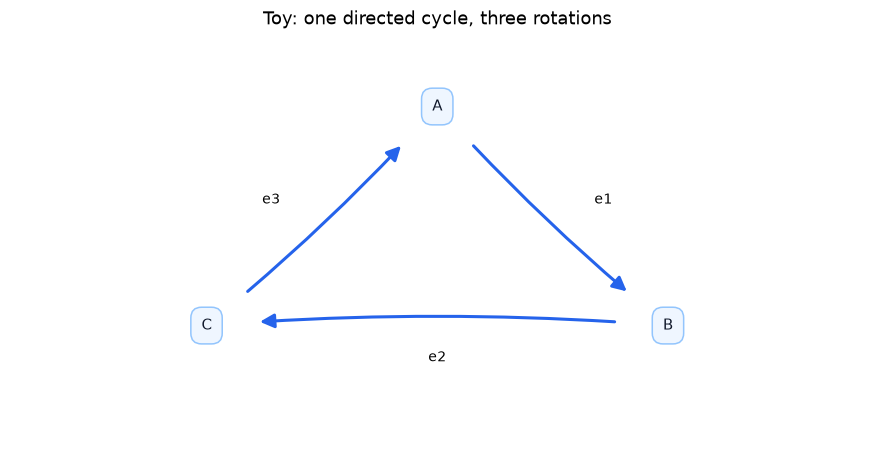

In [2]:
from src.motif.toy_cycle import run_demo
from src.motif.presentation import draw_graph

toy = run_demo(session.spark)
display(toy)
draw_graph({'A':'A', 'B':'B', 'C':'C'},
           [('A','B','e1'), ('B','C','e2'), ('C','A','e3')],
           'Toy: one directed cycle, three rotations')


## 3 · Baseline của Task 3

Giữ đúng cycle ba đỉnh và relay TRANSFER → CASH_OUT >10.000 trong 24 giờ. Kết quả 0 cycle không được sửa thành một motif khác. 30 relay của baseline đều có nhãn 0; có 2 cặp cùng giờ chưa biết thứ tự thực.

Cell dưới **chạy lại truy vấn** và so các dòng bàn giao với CSV hiện có. Source: [motif_finding.py](../src/paysim/motif_finding.py), điều phối hiển thị: [presentation.py](../src/motif/presentation.py).


In [3]:
from src.motif.presentation import baseline_audit

baseline = baseline_audit(session.spark, 'paysim')
display(baseline.summary)
display(baseline.examples.head(5))


,dataset,raw_cycles,relay_pairs,same_hour,fraud_transfer_edges,fraud_cashout_edges
0,paysim,0,30,2,0,0


,source_account,middle_account,cashout_account,transfer_step,cashout_step,transfer_amount,cashout_amount,transfer_isFraud,cashout_isFraud
0,C1933517957,C1939958280,C232785081,24,37,265406.49,400729.53,0,0
1,C831358900,C874023329,C1468339976,34,47,1326914.02,292696.43,0,0
2,C1554009922,C874023329,C1468339976,36,47,149467.61,292696.43,0,0
3,C1739712760,C1360393616,C654237876,44,44,161654.47,75989.57,0,0
4,C1483406592,C2013691076,C1228316980,129,132,255345.27,433722.00,0,0


## 4 · Kiến trúc motif nâng cấp

| Feature | Mẫu / ý nghĩa |
|---|---|
| Fan-in | A → B ← C; có ít nhất một nguồn khác |
| Fan-out | A ← B → C; có ít nhất một đích khác |
| Relay | A → B → C; ba tài khoản khác nhau |
| Reciprocal | A → B → A; vòng hai tài khoản |
| Cycle 3 | A → B → C → A, thời gian tăng nghiêm ngặt |
| Role history | Số giao dịch vào/ra trước đó của người gửi/người nhận, kể cả sự vắng mặt của lịch sử |

Cửa sổ cố định **24 và 168 giờ**, quy đổi theo đơn vị của dataset. Witness luôn ở timestamp nhỏ hơn giao dịch hiện tại; các dòng cùng timestamp không làm chứng cứ cho nhau. Count là volume giao dịch, không phải số người khác nhau. Vòng hai tài khoản và ba tài khoản được đếm riêng.

Self-loop, FX và amount=0 không làm witness cho dòng tiền; vẫn giữ trong mẫu số đánh giá. Không so trực tiếp amount khác tiền tệ. Tài khoản/cặp chỉ có một timestamp có strict-past history bằng 0, được bỏ trước khi tạo marker; left join/fill-zero vẫn giữ đủ giao dịch. Counts dùng expiry events + unbounded prefix sums để tránh quét lại cửa sổ tại hub. Witness của cycle/reciprocal được giữ trực tiếp; fan-in/out/relay được truy vấn theo event ID khi cần giải thích, không sinh dày đặc cặp cạnh. Một giao dịch xuất hiện trong nhiều tổ hợp vẫn chỉ được dự đoán một lần.

PaySim thường thiếu tính liên tục của đường đi đủ để tìm fraud bằng relay/cycle. Vì thế phải kiểm định thông tin từ nơi nhận, fan-in/out và cả trường hợp chưa có lịch sử, thay vì nới ngưỡng để ép có vòng.

Source thuật toán: [features.py](../src/motif/features.py). Hướng dùng feature theo thời gian tham khảo [IBM AMLworld, Appendix D](https://arxiv.org/html/2306.16424v3#A4); đây là triển khai riêng, không tái hiện điểm số của bài báo.


### Protocol cố định trước đánh giá

- 3 fold mở rộng theo thời gian: train ≤40%, validate (40,50]; train ≤50%, validate (50,65]; train ≤65%, validate (65,80]. Giữ timestamp ties cùng tập.
- So **transaction-only** với **motif-assisted**, cùng cây quyết định độ sâu 5, cùng weighting và preprocessing. Thang amount q90 theo currency/type chỉ học từ prefix training. Không dùng raw account ID, absolute timestamp hoặc nhãn làm feature.
- Chọn family và score threshold theo mean validation F1, kiểm tra worst-fold/std, phá hòa ưu tiên mô hình đơn giản hơn. Có thể chọn transaction-only nếu motif không giúp; không ép chọn motif.
- Khóa rule rồi refit đến 80%; chấm phần sau 80%. Score từ cây có trọng số **không phải xác suất fraud đã hiệu chuẩn**.

**Giới hạn thực nghiệm:** phần test này đã được khám phá ở phiên bản trước; đây là **reused internal temporal holdout**, không phải benchmark mới chưa từng nhìn. Wilson 95% CI là khoảng mô tả theo giả định binomial; chưa hiệu chỉnh tương quan giữa giao dịch/tài khoản.

Source: [config.py](../src/motif/config.py), [modeling.py](../src/motif/modeling.py), [pipeline.py](../src/motif/pipeline.py).


In [4]:
from src.motif.config import AnalysisConfig
from src.motif.pipeline import prepare_experiment

config = AnalysisConfig()
experiment = prepare_experiment(session.spark, 'paysim', config=config)
display(experiment.support)
display(config.as_dict())


Features: star histories via expiry-prefix sums


Features: reciprocal and same-partner histories


Features: directed topology and chronological cycle evidence


,phase,transactions,fraud,first_step,last_step
0,initial_train,2568452,2306.0,1,206
1,validation_1,618040,399.0,207,239
2,validation_2,971880,722.0,240,303
3,validation_3,955512,536.0,304,355
4,reused_test,1248736,4250.0,356,743


{'windows_hours': (24, 168),
 'fold_fractions': (0.4, 0.5, 0.65, 0.8),
 'score_thresholds': (0.001,
  0.005,
  0.01,
  0.02,
  0.05,
  0.1,
  0.2,
  0.3,
  0.5,
  0.7,
  0.9,
  0.99),
 'tree_depth': 5,
 'minimum_leaf_rows': 50,
 'seed': 2026,
 'example_limit': 5,
 'driver_memory': '6g',
 'parallelism': 2}

### Chọn cấu hình trên validation

Feature builder không nhận nhãn. Bước chấm rủi ro dưới đây **có giám sát**: nó học từ nhãn training, rồi chọn threshold bằng validation. Việc kiểm soát dữ liệu nằm trong pipeline Python, dùng cùng API cho CLI và notebook.


Validation 1: transaction_only; training through 206, validation through 239


Validation 1: motif_assisted; training through 206, validation through 239


Validation 2: transaction_only; training through 239, validation through 303


Validation 2: motif_assisted; training through 239, validation through 303


Validation 3: transaction_only; training through 303, validation through 355


Validation 3: motif_assisted; training through 303, validation through 355


,family,threshold,mean_F1,worst_F1,std_F1,mean_precision,TP,FP,FN,transactions,folds
0,motif_assisted,0.70,0.133362,0.093220,0.047137,0.090216,456,4861,1201,2545432,3
1,motif_assisted,0.50,0.104351,0.083248,0.021742,0.058651,801,12920,856,2545432,3
2,motif_assisted,0.30,0.074827,0.063473,0.012791,0.039588,1149,27771,508,2545432,3
3,motif_assisted,0.20,0.074827,0.063473,0.012791,0.039588,1149,27771,508,2545432,3
4,motif_assisted,0.10,0.074827,0.063473,0.012791,0.039588,1149,27771,508,2545432,3
5,motif_assisted,0.05,0.074827,0.063473,0.012791,0.039588,1149,27771,508,2545432,3
6,motif_assisted,0.02,0.074827,0.063473,0.012791,0.039588,1149,27771,508,2545432,3
7,motif_assisted,0.01,0.074827,0.063473,0.012791,0.039588,1149,27771,508,2545432,3


{'family': 'motif_assisted',
 'threshold': 0.7,
 'mean_F1': 0.133362403833933,
 'worst_F1': 0.093220338983051,
 'std_F1': 0.047137105256357,
 'mean_precision': 0.090216463884472,
 'TP': 456,
 'FP': 4861,
 'FN': 1201,
 'transactions': 2545432,
 'folds': 3}

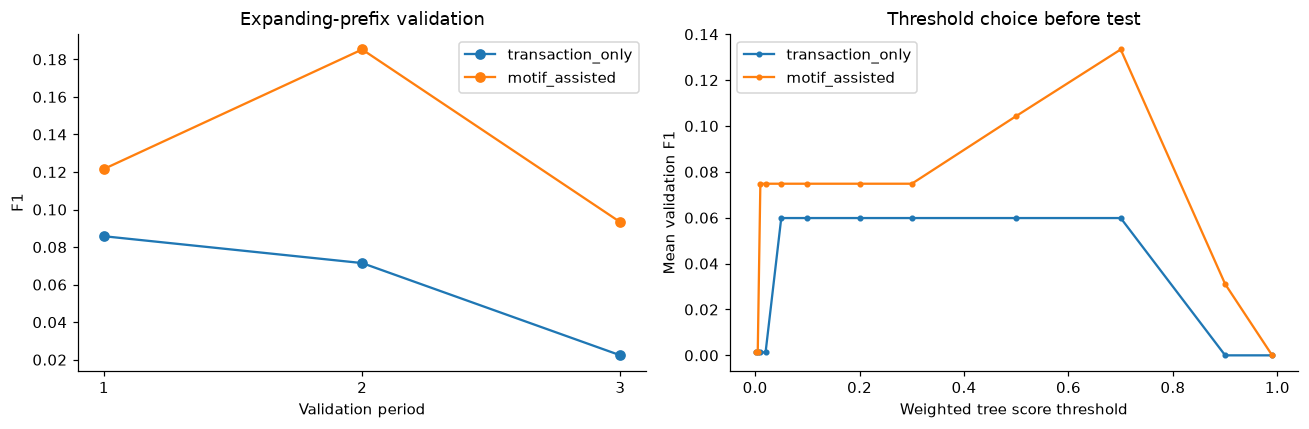

In [5]:
from src.motif.pipeline import run_walk_forward
from src.motif.presentation import plot_walk_forward

leaderboard = run_walk_forward(experiment)
display(leaderboard.head(8))
display(experiment.selection)
plot_walk_forward(experiment)


### Refit cấu hình đã khóa

Từ bước này không thay family/threshold theo kết quả test. Pipeline kiểm tra state và fingerprint cấu hình để phát hiện sửa rule sau validation.


In [6]:
from src.motif.pipeline import fit_final_models

training_info = fit_final_models(experiment)
display(training_info)


Refit frozen transaction_only; test is not used in fitting


Refit frozen motif_assisted; test is not used in fitting


{'transaction_only': {'train_end': 355,
  'rows': 5113884,
  'fraud': 3963,
  'positive_class_weight': 35.90831752145736,
  'status': 'fitted'},
 'motif_assisted': {'train_end': 355,
  'rows': 5113884,
  'fraud': 3963,
  'positive_class_weight': 35.90831752145736,
  'status': 'fitted'}}

### Đánh giá cuối: so công bằng với baseline transaction-only

Mẫu số gồm **mọi giao dịch** của test, không chỉ giao dịch nằm trong motif. Báo precision/recall/F1, average precision từ toàn bộ mức score của cây, CI và TP/FP/FN/TN. Một alert là đề nghị điều tra; không alert không chứng minh hợp pháp.


,model,threshold,TP,FP,FN,TN,precision,recall,F1,average_precision
0,transaction_only,0.7,889,713,3361,1243773,0.554931,0.209176,0.303828,0.124546
1,motif_assisted,0.7,1191,1489,3059,1242997,0.444403,0.280235,0.343723,0.207101


,model,precision_low95,precision_high95,recall_low95,recall_high95
0,transaction_only,0.530493,0.579107,0.197214,0.221664
1,motif_assisted,0.425683,0.463282,0.266936,0.293931


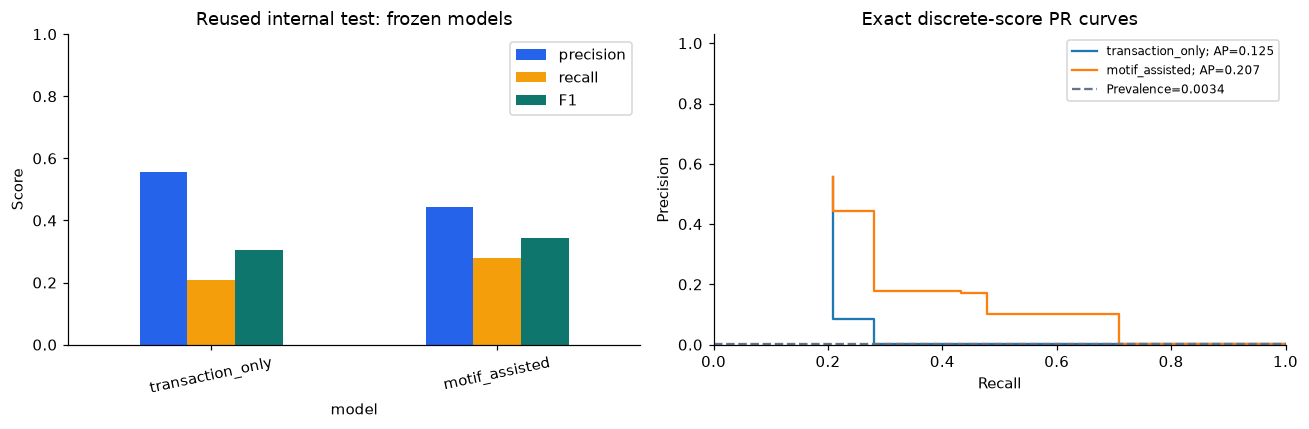

In [7]:
from src.motif.pipeline import evaluate_final_models
from src.motif.presentation import plot_test_results

metrics = evaluate_final_models(experiment)
display(metrics[['model','threshold','TP','FP','FN','TN','precision','recall','F1','average_precision']])
display(metrics[['model','precision_low95','precision_high95','recall_low95','recall_high95']])
plot_test_results(experiment)


### Motif có thực sự đóng góp?

Đọc ablation transaction-only ↔ motif-assisted trước khi kết luận. Feature importance mô tả cây đã học, không chứng minh quan hệ nhân quả. Coverage giữa các motif có thể chồng nhau, không cộng thành tổng fraud.


,motif,closing_transactions,fraud_closing_transactions
0,fanin,3486578,2342
1,fanout,5558,6
2,relay,94,0
3,reciprocal,0,0
4,cycle3,0,0


,feature,importance
0,receiver_in_168h,0.472933
1,type_index,0.286773
2,scaled_amount,0.240294
3,currency_index,0.000000
4,fx_payment,0.000000
5,sender_in_24h,0.000000
6,sender_out_24h,0.000000
7,unseen_amount_group,0.000000
8,receiver_in_24h,0.000000
9,receiver_out_24h,0.000000


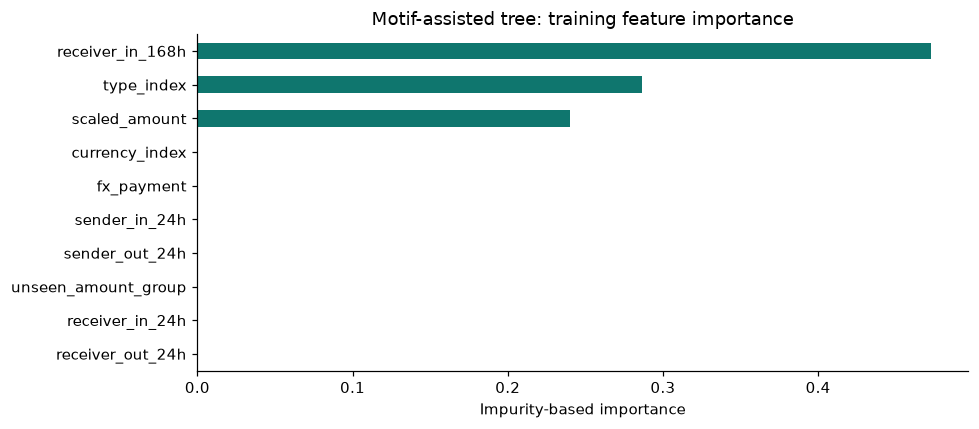

In [8]:
from src.motif.pipeline import motif_coverage
from src.motif.presentation import plot_feature_importance

display(motif_coverage(experiment))
display(experiment.models["motif_assisted"].importance().head(10))
plot_feature_importance(experiment)


### Phát hiện đúng, báo nhầm và bỏ sót

Hiển thị các trường hợp từ **mô hình được chọn trên validation**. Không thay bằng ví dụ từ truy vấn lọc nhãn. Một số TP có thể do thông tin giao dịch hoặc sự thiếu lịch sử, chứ không có motif nhiều cạnh dương tính.


TP — selected model, test period


,event_id,src,dst,type,amount,payment_currency,risk_score,isFraud
0,3006941,C902008507,C1795644557,CASH_OUT,5952739.30,PaySim unit,0.838869,1.0
1,656503,C1879989290,C1527777046,CASH_OUT,10000000.00,PaySim unit,0.838869,1.0
2,3066053,C1918267923,C1297204700,CASH_OUT,2239461.29,PaySim unit,0.838869,1.0
3,3065322,C393707500,C730262166,CASH_OUT,790332.43,PaySim unit,0.838869,1.0
4,8592182042,C376454889,C1559513408,CASH_OUT,4177467.46,PaySim unit,0.838869,1.0


FP — selected model, test period


,event_id,src,dst,type,amount,payment_currency,risk_score,isFraud
0,8591350199,C510789835,C321394947,CASH_OUT,826280.21,PaySim unit,0.838869,0.0
1,617230,C1015088666,C960291359,CASH_OUT,682153.73,PaySim unit,0.838869,0.0
2,8590570208,C1807710428,C1057872123,CASH_OUT,824520.24,PaySim unit,0.838869,0.0
3,8591358561,C878500608,C926185200,CASH_OUT,836403.07,PaySim unit,0.838869,0.0
4,2218319,C350407897,C2108067231,CASH_OUT,724078.49,PaySim unit,0.838869,0.0


FN — selected model, test period


,event_id,src,dst,type,amount,payment_currency,risk_score,isFraud
0,3022138,C854622383,C1455552961,TRANSFER,7360.15,PaySim unit,0.651506,1.0
1,672672,C1335541144,C887702391,TRANSFER,74921.74,PaySim unit,0.651506,1.0
2,8592179372,C1843682589,C117985558,TRANSFER,10358.27,PaySim unit,0.651506,1.0
3,1456824,C1075724931,C464861885,TRANSFER,122639.34,PaySim unit,0.651506,1.0
4,8591396783,C2118754392,C650299335,TRANSFER,105733.45,PaySim unit,0.651506,1.0


,event_id,src,dst,step,amount,payment_currency,isFraud,role
0,8591339329,C185256069,C1795644557,353,608278.66,PaySim unit,0.0,past witness
1,3006941,C902008507,C1795644557,356,5952739.30,PaySim unit,1.0,current alert


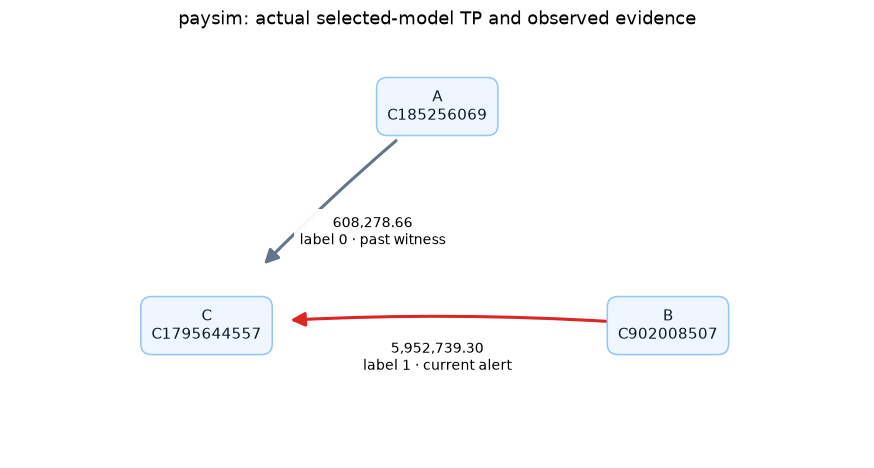

In [9]:
from src.motif.presentation import show_examples, motif_evidence, plot_evidence

show_examples(experiment)
evidence = motif_evidence(experiment)
display(evidence)
plot_evidence(evidence, session.dataset)


### Kết luận PaySim từ output đã chạy

CV chọn **motif-assisted, weighted score ≥0,70**. Đây không phải khẳng định xác suất fraud ≥70%.

| Model | Test TP | FP | FN | Precision | Recall | F1 | Average precision |
|---|---:|---:|---:|---:|---:|---:|---:|
| Transaction-only | 889 | 713 | 3.361 | 55,49% | 20,92% | 30,38% | 12,45% |
| Motif-assisted | 1.191 | 1.489 | 3.059 | 44,44% | 28,02% | 34,37% | 20,71% |

Mẫu số: **1.248.736 giao dịch / 4.250 fraud**. So với cùng cây không có graph feature, có thêm **302 TP** và **776 FP**: recall/F1/AP tăng, precision giảm. Đây là bằng chứng về đóng góp của bộ feature trong protocol này, chưa phải chứng minh mọi motif mang ý nghĩa gian lận hoặc một mô hình sẵn sàng triển khai.

**Đóng góp cần gọi đúng tên:** cây PaySim cuối sử dụng chủ yếu `receiver_in_168h`, loại giao dịch và amount đã chuẩn hóa; các feature count motif dương tính không được chọn để split trong cây này. Vì vậy, ablation hỗ trợ giá trị của **bộ graph context**, chưa chứng minh fan-in/cycle count có đóng góp độc lập khỏi role history. Không diễn giải F1 tăng thành việc đã tìm được vòng fraud.

Cycle và reciprocal vẫn bằng 0; không tạo vòng giả. Cần đọc role histories và sự thiếu lịch sử bên cạnh motif dương tính. Ví dụ TP có fan-in gồm cạnh cảnh báo nhãn 1 và cạnh quá khứ nhãn 0; không suy ra mọi cạnh trong motif đều gian lận. Các cạnh vẽ đều được truy từ dữ liệu thật. Mean validation F1 **13,34%**, worst-fold **9,32%**, độ lệch chuẩn **4,71 điểm phần trăm** cho thấy kết quả thay đổi đáng kể theo giai đoạn. Test đã được khám phá trước; cần dữ liệu mới để kiểm chứng khả năng tổng quát hóa.

### Bàn giao để kết hợp PageRank/LPA

Giữ feature, witness, `event_key`, `event_id`, source/target và thời điểm. `event_key` là content fingerprint, **không duy nhất khi dữ liệu có dòng trùng**; `event_id` giữ từng dòng trong cùng lần chạy. Join PageRank/LPA theo tài khoản từ snapshot đến thời điểm quyết định. Không dùng tỷ lệ fraud của nhãn test làm feature.

CLI có thể xuất model, training amount scales, report, validation scores, ví dụ và run manifest có hash; `--export-features` xuất thêm Parquet cho tích hợp. Notebook này chỉ giữ output nhúng.


In [10]:
# Giải phóng cache của experiment trước phần review tiếp theo.
experiment.close()


## 5 · Review và final lý thuyết PageRank 3.3

Với vector cột, ma trận chuyển tiếp phải column-stochastic. Sửa dangling columns bằng phân phối đều, rồi thêm teleportation:

$$G=d\widetilde{M}+(1-d)\mathbf{1}\mathbf{1}^{T}/n.$$

Ví dụ toán tự tạo kiểm chứng mất probability mass ở sink và việc teleportation thoát trap. Đây là nhiệm vụ review 25–28/9 của Khánh, tách khỏi thực nghiệm motif. PageRank cao không đồng nghĩa fraud.

Source: [reviews.py](../src/motif/reviews.py); lý thuyết chung: [PartA_Theory.md](../docs/PartA_Theory.md).


,account,d=1,d=0.85
0,A,0.0,0.0500
1,B,0.0,0.0925
2,T,1.0,0.8575


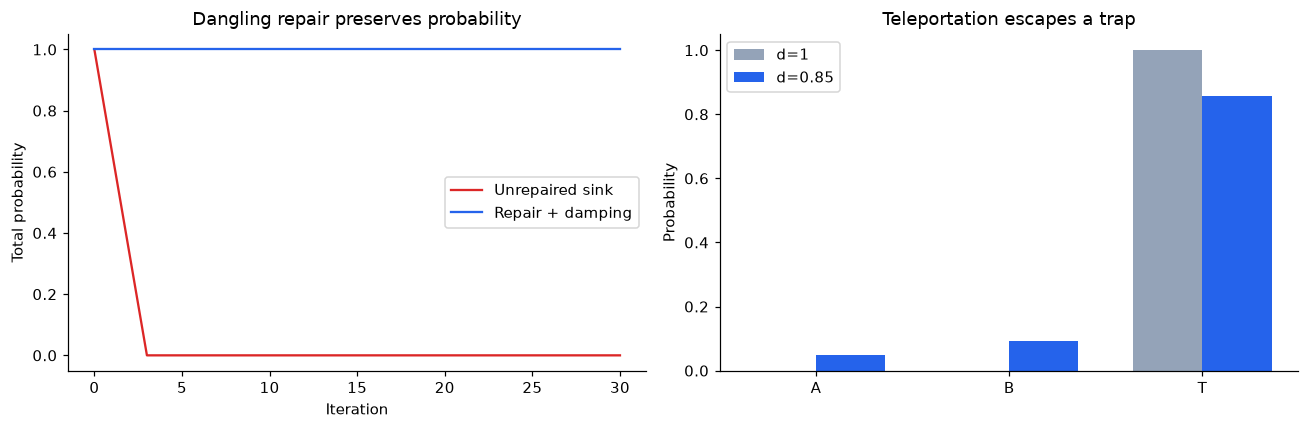

In [11]:
from src.motif.reviews import review_pagerank
from src.motif.presentation import plot_pagerank

pagerank = review_pagerank()
display(pagerank['table'])
plot_pagerank(pagerank)


## 6 · Chốt kết quả và phiên bản code

Khi bảo vệ: nêu baseline → motif/feature → protocol → ablation/test → một TP/FP/FN → giới hạn. Không dùng số test để chọn lại cấu hình. PASS kỹ thuật không xác nhận chất lượng detector hay phê duyệt của người review.

Các nhiệm vụ của Khánh được giữ: toy graph.find (21/9), review/final PageRank 3.3 (25–28/9), Task 3 PaySim (30/9–3/10). Phần mở rộng v2 bổ sung pipeline, motifs theo thời gian và đánh giá chấm rủi ro; không thay số baseline để ép kết quả.


In [12]:
from src.motif.presentation import source_provenance

display(source_provenance())
display(session.close())


,source,sha256
0,src/motif/__init__.py,f42e40287d3de4006d8e0d042b61b38f5726b414b2b949...
1,src/motif/config.py,ced62e7f1f0832ea19b58ff3b479cab960bc9e3eb34197...
2,src/motif/evaluation.py,8746e78334ae5fe5206d68b733dee439254e41c2c01280...
3,src/motif/features.py,880195183191cc9b984d80defd16a77ce5841a96d1b33b...
4,src/motif/modeling.py,54568d9da7a194ad0b651fa667f6027ebc044ba5307f42...
5,src/motif/pipeline.py,f857c8488e47a88f8c282fc294c1f9958577900dd280d0...
6,src/motif/presentation.py,1b0bea60b43f7fbb94ba841642a9c21903e208c708d938...
7,src/motif/reviews.py,ed6ccc593b0d1f35f06fdb195e57304d65b0d26d76cfaf...
8,src/motif/toy_cycle.py,44caa76842030eb834f9e854fd7f8b18cd5aabf2498f47...
9,src/common/graph_utils.py,b656fc4d7767fa1a3cc9bdb8e66101b0f6272daf01d586...


,setting,value
0,dataset,paysim
1,finished_utc,2026-10-18T19:02:44.508090+00:00
2,elapsed_seconds,1052.6
3,execution,Completed; performance is reported separately
4,cpu_hard_cap_percent,10
5,max_logical_cpus,2
6,job_commit_cap_gib,10.0
7,peak_job_commit_gib,7.51
8,minimum_available_ram_gib,14.62
9,maximum_host_cpu_percent,27.3
